<a href="https://colab.research.google.com/github/Kolawole-Toheeb/diabetes-readmission-prediction/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/Kolawole-Toheeb/diabetes-readmission-prediction/main/data/diabetic_data.csv"
df = pd.read_csv(url)
print(df.shape)

df = df.replace('?', pd.NA)

print(df['readmitted'].value_counts())
print(df.isnull().mean().sort_values(ascending=False).head(10))
df.head()

/tmp/ipykernel_5330/2150242145.py:4: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(url)


(101766, 50)
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64
weight               0.968585
max_glu_serum        0.947468
A1Cresult            0.832773
medical_specialty    0.490822
payer_code           0.395574
race                 0.022336
diag_3               0.013983
diag_2               0.003518
diag_1               0.000206
patient_nbr          0.000000
dtype: float64


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
df = pd.read_csv(url, low_memory=False)
df = df.replace('?', pd.NA)

# 1. Target: readmitted within 30 days (1 = yes, 0 = no)
df['readmit_30'] = (df['readmitted'] == '<30').astype(int)

# 2. Remove patients who died or went to hospice (they cannot be readmitted)
not_readmittable = [11, 13, 14, 19, 20, 21]
df = df[~df['discharge_disposition_id'].isin(not_readmittable)]

# 3. Keep one visit per patient (the same patient must not be in train and test)
df = df.sort_values('encounter_id').drop_duplicates(subset='patient_nbr', keep='first')

# 4. Drop columns we don't need
df = df.drop(columns=['encounter_id', 'patient_nbr', 'weight', 'readmitted'])

# 5. These ID columns are categories, not numbers
for c in ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']:
    df[c] = df[c].astype(str)

# 6. Fill missing values in text columns with 'Unknown'
for c in df.select_dtypes(exclude='number').columns:
    df[c] = df[c].fillna('Unknown')

print(df.shape)
print(df['readmit_30'].mean())
print(df.isnull().sum().sum())

(69990, 47)
0.08979854264894985
0


numeric: 8 categorical: 38
readmit_30
0    0.910201
1    0.089799
Name: proportion, dtype: float64
                    min       mean    max
time_in_hospital    1.0   4.273296   14.0
num_lab_procedures  1.0  42.875482  132.0
num_procedures      0.0   1.425432    6.0
num_medications     1.0  15.665309   81.0
number_outpatient   0.0   0.279583   42.0
number_emergency    0.0   0.103901   42.0
number_inpatient    0.0   0.176268   12.0
number_diagnoses    1.0   7.224118   16.0


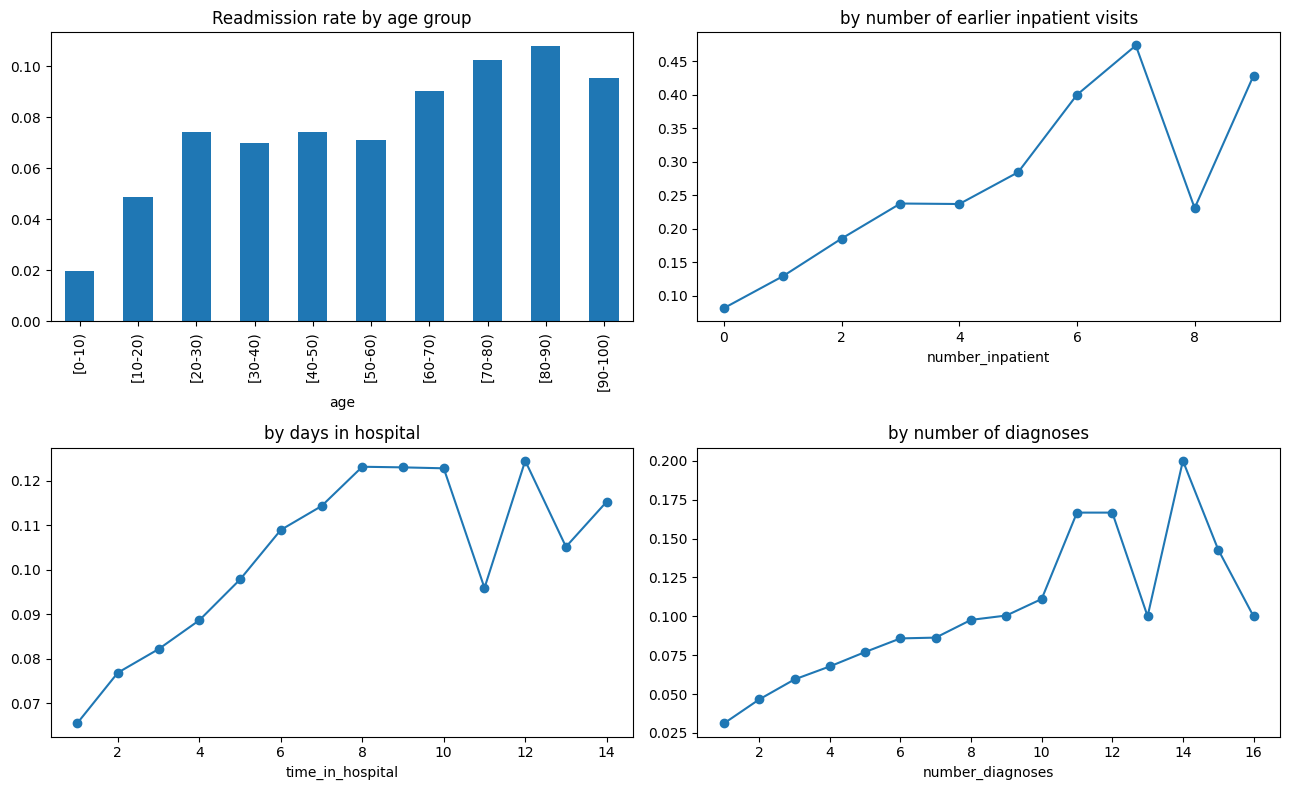

Numeric features, AUC against the target:
time_in_hospital      0.560
number_inpatient      0.548
num_medications       0.543
number_diagnoses      0.542
num_lab_procedures    0.533
number_emergency      0.514
number_outpatient     0.510
num_procedures        0.503
dtype: float64
Categorical features, mutual information:
diag_1                      0.0098
diag_3                      0.0081
discharge_disposition_id    0.0076
diag_2                      0.0075
medical_specialty           0.0017
age                         0.0014
payer_code                  0.0010
diabetesMed                 0.0004
insulin                     0.0003
admission_type_id           0.0001
dtype: float64


In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, mutual_info_score

target = 'readmit_30'
numeric = list(df.select_dtypes(include='number').columns.drop(target))
categorical = list(df.select_dtypes(exclude='number').columns)
print("numeric:", len(numeric), "categorical:", len(categorical))

# 1. Target
print(df[target].value_counts(normalize=True))

# 2. Ranges of the numeric columns
print(df[numeric].describe().T[['min', 'mean', 'max']])

# 3. Readmission rate against some features
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
df.groupby('age')[target].mean().plot(kind='bar', ax=axes[0, 0], title='Readmission rate by age group')
df.groupby('number_inpatient')[target].mean().head(10).plot(ax=axes[0, 1], marker='o', title='by number of earlier inpatient visits')
df.groupby('time_in_hospital')[target].mean().plot(ax=axes[1, 0], marker='o', title='by days in hospital')
df.groupby('number_diagnoses')[target].mean().plot(ax=axes[1, 1], marker='o', title='by number of diagnoses')
plt.tight_layout()
plt.show()

# 4. Feature importance
num_auc = {}
for c in numeric:
    a = roc_auc_score(df[target], df[c])
    num_auc[c] = round(max(a, 1 - a), 3)
print("Numeric features, AUC against the target:")
print(pd.Series(num_auc).sort_values(ascending=False))

mi = {c: mutual_info_score(df[c], df[target]) for c in categorical}
print("Categorical features, mutual information:")
print(pd.Series(mi).sort_values(ascending=False).head(10).round(4))

In [6]:
# ---- Cell A: group diagnosis codes, then split the data ----
def diag_group(code):
    if code == 'Unknown':
        return 'Unknown'
    if str(code).startswith(('V', 'E')):
        return 'Other'
    try:
        n = float(code)
    except ValueError:
        return 'Other'
    if 390 <= n <= 459 or n == 785: return 'Circulatory'
    if 460 <= n <= 519 or n == 786: return 'Respiratory'
    if 520 <= n <= 579 or n == 787: return 'Digestive'
    if 250 <= n < 251: return 'Diabetes'
    if 800 <= n <= 999: return 'Injury'
    if 710 <= n <= 739: return 'Musculoskeletal'
    if 580 <= n <= 629 or n == 788: return 'Genitourinary'
    if 140 <= n <= 239: return 'Neoplasms'
    return 'Other'

for c in ['diag_1', 'diag_2', 'diag_3']:
    df[c] = df[c].apply(diag_group)

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer

target = 'readmit_30'
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1, stratify=df[target])
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1, stratify=df_full_train[target])

y_train = df_train[target].values
y_val = df_val[target].values

categorical = list(df.select_dtypes(exclude='number').columns)
numeric = list(df.select_dtypes(include='number').columns.drop(target))
features = categorical + numeric

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))
print(X_train.shape, X_val.shape)
print(df['diag_1'].value_counts())

(41994, 264) (13998, 264)
diag_1
Circulatory        21390
Other              12124
Respiratory         9491
Digestive           6488
Diabetes            5748
Injury              4696
Musculoskeletal     4064
Genitourinary       3441
Neoplasms           2538
Unknown               10
Name: count, dtype: int64


In [7]:
# ---- Cell B: train and tune several models, compare validation AUC ----
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
import xgboost as xgb

results = []

# 1. Logistic regression (linear model)
for C in [0.01, 0.1, 1.0]:
    m = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    m.fit(X_train, y_train)
    auc = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
    results.append(('LogisticRegression', f'C={C}', auc))

# 2. Decision tree
for d in [3, 5, 7, 10]:
    m = DecisionTreeClassifier(max_depth=d, min_samples_leaf=50, random_state=1)
    m.fit(X_train, y_train)
    auc = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
    results.append(('DecisionTree', f'max_depth={d}', auc))

# 3. Random forest
for d in [5, 10, 15]:
    m = RandomForestClassifier(n_estimators=100, max_depth=d, min_samples_leaf=20,
                               random_state=1, n_jobs=-1)
    m.fit(X_train, y_train)
    auc = roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])
    results.append(('RandomForest', f'max_depth={d}', auc))

# 4. XGBoost
dtrain = xgb.DMatrix(X_train, label=y_train)
dval = xgb.DMatrix(X_val, label=y_val)
for eta in [0.05, 0.1]:
    for d in [3, 5]:
        params = {'eta': eta, 'max_depth': d, 'min_child_weight': 5,
                  'objective': 'binary:logistic', 'eval_metric': 'auc',
                  'nthread': 8, 'seed': 1, 'verbosity': 0}
        m = xgb.train(params, dtrain, num_boost_round=200)
        auc = roc_auc_score(y_val, m.predict(dval))
        results.append(('XGBoost', f'eta={eta}, max_depth={d}', auc))

res = pd.DataFrame(results, columns=['model', 'parameters', 'val_auc'])
print(res.sort_values('val_auc', ascending=False).round(4).to_string(index=False))

             model            parameters  val_auc
           XGBoost  eta=0.1, max_depth=5   0.6421
           XGBoost eta=0.05, max_depth=5   0.6419
           XGBoost  eta=0.1, max_depth=3   0.6406
      RandomForest          max_depth=15   0.6394
      RandomForest          max_depth=10   0.6390
           XGBoost eta=0.05, max_depth=3   0.6381
LogisticRegression                 C=0.1   0.6361
LogisticRegression                C=0.01   0.6350
LogisticRegression                 C=1.0   0.6347
      RandomForest           max_depth=5   0.6304
      DecisionTree           max_depth=7   0.6150
      DecisionTree           max_depth=5   0.6141
      DecisionTree          max_depth=10   0.6094
      DecisionTree           max_depth=3   0.6041


In [8]:
# ---- Cell C: final model (train + validation), tested once on the test set ----
y_full_train = df_full_train[target].values
y_test = df_test[target].values

dv_final = DictVectorizer(sparse=False)
X_full_train = dv_final.fit_transform(df_full_train[features].to_dict(orient='records'))
X_test = dv_final.transform(df_test[features].to_dict(orient='records'))

dfull = xgb.DMatrix(X_full_train, label=y_full_train)
dtest = xgb.DMatrix(X_test, label=y_test)

params = {'eta': 0.1, 'max_depth': 5, 'min_child_weight': 5,
          'objective': 'binary:logistic', 'eval_metric': 'auc',
          'nthread': 8, 'seed': 1, 'verbosity': 0}
final_model = xgb.train(params, dfull, num_boost_round=200)

print("Test AUC:", round(roc_auc_score(y_test, final_model.predict(dtest)), 4))

# Most important features (by gain)
gain = final_model.get_score(importance_type='gain')
imp = pd.Series({dv_final.feature_names_[int(k[1:])]: v for k, v in gain.items()})
print(imp.sort_values(ascending=False).head(10).round(2))

Test AUC: 0.6534
discharge_disposition_id=1     48.68
number_inpatient               27.16
discharge_disposition_id=22    22.91
discharge_disposition_id=6     12.33
discharge_disposition_id=5     12.24
discharge_disposition_id=3     10.81
diag_1=Other                   10.41
diag_1=Musculoskeletal         10.28
diag_3=Genitourinary            8.90
discharge_disposition_id=2      8.74
dtype: float64
